In [10]:
import os
import numpy as np
import pandas as pd
import torch
from torch.utils.data import Dataset, DataLoader
from scipy.io import loadmat
from scipy.signal import resample
from sklearn.model_selection import train_test_split
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.cuda.amp import autocast, GradScaler
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score
from tqdm import tqdm


In [11]:

class ECGDataset(Dataset):
    def __init__(self, signals, labels_pattern, labels_lead):
        self.signals = torch.tensor(signals, dtype=torch.float32)
        self.labels_pattern = torch.tensor(labels_pattern, dtype=torch.float32)
        self.labels_lead = torch.tensor(labels_lead, dtype=torch.float32)

    def __len__(self):
        return len(self.signals)

    def __getitem__(self, idx):
        return self.signals[idx], self.labels_pattern[idx], self.labels_lead[idx]

# Ruta de los datos
root = r'C:\Users\albai\Documents\proyecto_patrones\all_signals'
all_signals = os.listdir(root)
anotaciones = pd.read_csv(r"C:\Users\albai\Documents\proyecto_patrones\all_anotaciones.csv", sep=';')

label, pattern, sig, len_sig = [], [], [], []

for filename in all_signals:
    mat_data = loadmat(os.path.join(root, filename))
    
    if 'ecg_signal' in mat_data:
        s = mat_data['ecg_signal'][0]
    elif 'ecg_guardar' in mat_data:
        s = mat_data['ecg_guardar'][0]
    else:
        continue  # Saltar archivo si no contiene la clave esperada
    
    if len(s) > 300:
        s = resample(s, 252)
    
    sig.append(s)
    len_sig.append(len(s))
    
    aux = filename.split('_')
    label.append(aux[4] if len(aux) == 6 else aux[3])
    pattern.append(aux[5][:-4] if len(aux) == 6 else aux[4][:-4])


#Standarization
sig = (sig - np.mean(sig, axis=1, keepdims=True)) / np.std(sig, axis=1, keepdims=True)


# Convertir etiquetas
label_map = {'V1': 0, 'V2': 1, 'V3': 2, 'V4': 3, 'V5': 4, 'V6': 5}
labels_code = np.array([label_map[l] for l in label], dtype=np.int64)

pattern_code = np.array([1 if p == '1' else 0 for p in pattern], dtype=np.float32)
#quitamos one_hot
#labels_oh = np.eye(6)[labels_code]  # One-hot encoding

# Extraer identificadores de paciente
patient_ids = [fname.split('_')[0] for fname in all_signals]

# Agrupar señales por paciente
patient_dict = {}
for i, patient in enumerate(patient_ids):
    if patient not in patient_dict:
        patient_dict[patient] = {"signals": [], "pattern_code": [], "labels_oh": []}
    patient_dict[patient]["signals"].append(sig[i])
    patient_dict[patient]["pattern_code"].append(pattern_code[i])
    patient_dict[patient]["labels_oh"].append(labels_code[i])

# División train/test asegurando separación de pacientes
unique_patients = list(patient_dict.keys())
train_patients, test_patients = train_test_split(unique_patients, test_size=0.3, random_state=42)

# Asignar señales a los conjuntos de train y test
sig_train, y_train_pattern, y_train_lead = [], [], []
sig_test_val, y_test_val_pattern, y_test_val_lead = [], [], []

for patient in train_patients:
    sig_train.extend(patient_dict[patient]["signals"])
    y_train_pattern.extend(patient_dict[patient]["pattern_code"])
    y_train_lead.extend(patient_dict[patient]["labels_oh"])

for patient in test_patients:
    sig_test_val.extend(patient_dict[patient]["signals"])
    y_test_val_pattern.extend(patient_dict[patient]["pattern_code"])
    y_test_val_lead.extend(patient_dict[patient]["labels_oh"])

# Convertir a numpy arrays
sig_train = np.array(sig_train)
y_train_pattern = np.array(y_train_pattern)
y_train_lead = np.array(y_train_lead)

sig_test_val = np.array(sig_test_val)
y_test_val_pattern = np.array(y_test_val_pattern)
y_test_val_lead = np.array(y_test_val_lead)

# Dividir test en test y validación
sig_test, sig_val, y_test_pattern, y_val_pattern, y_test_lead, y_val_lead = train_test_split(
    sig_test_val, y_test_val_pattern, y_test_val_lead, test_size=0.5, random_state=42)

# Agregar la dimensión del canal (1) a las señales antes de pasarlas al Dataset
sig_train = sig_train[:, np.newaxis, :]
sig_val = sig_val[:, np.newaxis, :]
sig_test = sig_test[:, np.newaxis, :]


# Crear datasets de PyTorch
dataset_train = ECGDataset(sig_train, y_train_pattern, y_train_lead)
dataset_val = ECGDataset(sig_val, y_val_pattern, y_val_lead)
dataset_test = ECGDataset(sig_test, y_test_pattern, y_test_lead)

# Crear DataLoaders
dataloader_train = DataLoader(dataset_train, batch_size=32, shuffle=True)
dataloader_val = DataLoader(dataset_val, batch_size=32, shuffle=False)
dataloader_test = DataLoader(dataset_test, batch_size=32, shuffle=False)

# Verificar tamaños de los conjuntos
print(f"Tamaños -> Train: {len(dataset_train)}, Val: {len(dataset_val)}, Test: {len(dataset_test)}")


Tamaños -> Train: 6156, Val: 2218, Test: 2218


In [ ]:
class IdentityBlock(nn.Module):
    def __init__(self, in_channels, filters, kernel_size):
        super(IdentityBlock, self).__init__()
        F1, F2, F3 = filters

        self.conv1 = nn.Conv1d(in_channels, F1, kernel_size=1, stride=1, padding=0)
        self.bn1 = nn.BatchNorm1d(F1)
        self.activation1 = nn.LeakyReLU()
        self.dropout1 = nn.Dropout1d(0.3)

        self.conv2 = nn.Conv1d(F1, F2, kernel_size=kernel_size, stride=1, padding=kernel_size//2)  
        self.bn2 = nn.BatchNorm1d(F2)
        self.activation2 = nn.LeakyReLU()
        

        self.conv3 = nn.Conv1d(F2, F3, kernel_size=1, stride=1, padding=0)
        self.bn3 = nn.BatchNorm1d(F3)
        self.activation_out = nn.LeakyReLU()


    def forward(self, x):
        shortcut = x  

        x = self.conv1(x)
        x = self.bn1(x)
        x = self.activation1(x)
        x = self.dropout1(x)

        x = self.conv2(x)
        x = self.bn2(x)
        x = self.activation2(x)
        #x = self.dropout2(x)

        x = self.conv3(x)
        x = self.bn3(x)

        x += shortcut  
        x = self.activation_out(x)

        return x

class ConvolutionalBlock(nn.Module):
    def __init__(self, in_channels, filters, kernel_size, stride=2):
        super(ConvolutionalBlock, self).__init__()
        F1, F2, F3 = filters

        self.conv1 = nn.Conv1d(in_channels, F1, kernel_size=1, stride=stride, padding=0)
        self.bn1 = nn.BatchNorm1d(F1)
        self.activation1 = nn.LeakyReLU()
        self.dropout1 = nn.Dropout1d(0.3)

        self.conv2 = nn.Conv1d(F1, F2, kernel_size=kernel_size, stride=1, padding=kernel_size//2)
        self.bn2 = nn.BatchNorm1d(F2)
        self.activation2 = nn.LeakyReLU()
      

        self.conv3 = nn.Conv1d(F2, F3, kernel_size=1, stride=1, padding=0)
        self.bn3 = nn.BatchNorm1d(F3)

        self.shortcut = nn.Sequential(
            nn.Conv1d(in_channels, F3, kernel_size=1, stride=stride, padding=0),
            nn.BatchNorm1d(F3)
        )

        self.activation_out = nn.LeakyReLU() #aqui había una silu

    def forward(self, x):
        shortcut = self.shortcut(x)

        x = self.conv1(x)
        x = self.bn1(x)
        x = self.activation1(x)
        x = self.dropout1(x)

        x = self.conv2(x)
        x = self.bn2(x)
        x = self.activation2(x)
        #x = self.dropout2(x)

        x = self.conv3(x)
        x = self.bn3(x)

        x += shortcut  
        x = self.activation_out(x)

        return x

class ResNet1D(nn.Module):
    def __init__(self, input_channels, num_classes1):
        super(ResNet1D, self).__init__()
        self.conv1 = nn.Conv1d(input_channels, 64, kernel_size=7, stride=2, padding=3)
        self.bn1 = nn.BatchNorm1d(64)  #Revisar el batch 
        self.activation = nn.LeakyReLU()
        self.pool1 = nn.MaxPool1d(kernel_size=3, stride=2, padding=1)

        self.conv_block2a = ConvolutionalBlock(64, [128, 128, 256], kernel_size=3, stride=1)
        self.id_block2b = IdentityBlock(256, [128, 128, 256], kernel_size=3)
        self.id_block2c = IdentityBlock(256, [128, 128, 256], kernel_size=3)

        self.conv_block3a = ConvolutionalBlock(256, [128, 128, 512], kernel_size=3, stride=2)
        self.id_block3b = IdentityBlock(512, [128, 128, 512], kernel_size=3)
        self.id_block3c = IdentityBlock(512, [128, 128, 512], kernel_size=3)
        self.id_block3d = IdentityBlock(512, [128, 128, 512], kernel_size=3)

        self.avgpool = nn.AdaptiveAvgPool1d(1)
        
        # Fully connected layers
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(512, 256)  # 512 es la salida después de Global Average Pooling
        self.relu1 = nn.LeakyReLU()
        self.fc2 = nn.Linear(256, 128)
        self.relu2 = nn.LeakyReLU()  

        # Dos salidas
        self.pattern_output = nn.Linear(128, num_classes1)  # Para clasificación binaria (BCEWithLogitsLoss)
        
        #self.lead_output = nn.Linear(128, num_classes2) #Para clasificación multiclase 
    
    def forward(self, x):
        x = self.activation(self.bn1(self.conv1(x)))
        x = self.pool1(x)

        x = self.conv_block2a(x)
        x = self.id_block2b(x)
        x = self.id_block2c(x)

        x = self.conv_block3a(x)
        x = self.id_block3b(x)
        x = self.id_block3c(x)
        x = self.id_block3d(x)

        x = self.avgpool(x)  # Reducción a [batch, channels, 1]
        x = torch.flatten(x, start_dim=1)  # Asegurar [batch, 512]

        x = self.fc1(x)
        x = self.relu1(x)
        x = self.fc2(x)
        x = self.relu2(x)

        # Salidas
        output1 = self.pattern_output(x)  # Logits para BCEWithLogitsLoss
        #output2 = self.lead_output(x)
        return output1




In [13]:
from collections import Counter

targets_all = []
for _, targets1, targets2 in dataloader_train:
    targets_all.extend(targets1.numpy())

counts = Counter(targets_all)
print(counts) 

Counter({np.float32(0.0): 4894, np.float32(1.0): 1262})


In [14]:
# Inicialización del modelo con optimización torch.compile
device = "cuda"
model = ResNet1D(input_channels=1, num_classes1=1).to(device)

num_neg = counts[0]
num_pos = counts[1]
pos_weight = torch.tensor([num_neg / num_pos]).to(device)

# model = ResNet1D(input_channels=1, num_classes1=6, num_classes2=1).to("cuda")
# model = torch.compile(model)  # Optimización en PyTorch 2.0+


criterion1 = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
#criterion2 = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)

# Configurar OneCycleLR
#scheduler = optim.lr_scheduler.OneCycleLR(optimizer, max_lr=1e-3, epochs=30, steps_per_epoch=len(dataloader_train))
loss_all=[]
loss_1=[]
loss_2=[]

val_loss_all = []
val_loss_1 = []
val_loss_2 = []

# Entrenamiento sin autocast
for epoch in range(100):
    
    model.train()

    epoch_loss1=0
    epoch_loss2=0
    total_loss= 0

    print(f"epoch {epoch}")
    for inputs, targets1, targets2 in tqdm(dataloader_train):
        inputs, targets1= inputs.to(device), targets1.to(device).to(torch.float32)

        optimizer.zero_grad()
        outputs1= model(inputs)  # outputs1: [batch, 1], outputs2: [batch, 6] #forward del modelo 

        loss1 = criterion1(outputs1, targets1.unsqueeze(1))  # Asegurar forma [batch, 1]
        #loss2 = criterion2(outputs2, targets2)
        #loss = loss1 + loss2

        #backward propagation
        loss1.backward()

        #ajusting learning weights
        optimizer.step()

        epoch_loss1 += loss1.item()
        #epoch_loss2 += loss2.item()
        

        #total_loss += loss.item()
    print(f"loss binary train: {epoch_loss1}")

    #print(f"loss multiclass train: {epoch_loss2}")

    # loss_all.append(total_loss / len(dataloader_train))
    loss_1.append(epoch_loss1 / len(dataloader_train))
    # loss_2.append(epoch_loss2 / len(dataloader_train))

    #Validacion

    model.eval()

    val_epoch_loss1 = 0
    val_epoch_loss2 = 0
    val_total_loss = 0

    val_correct = 0
    val_total = 0

    val_preds_all = []
    val_targets_all = []
    val_probs_all = []

    with torch.no_grad():
        for inputs, targets1, targets2 in dataloader_val:
            inputs = inputs.to(device)
            targets1 = targets1.to(device).to(torch.float32)
            #targets2 = targets2.to(device).to(torch.float32)

            outputs1= model(inputs)

            loss1 = criterion1(outputs1, targets1.unsqueeze(1))
            # loss2 = criterion2(outputs2, targets2)
            # loss = loss1 + loss2

            val_epoch_loss1 += loss1.item()
            
            # val_epoch_loss2 += loss2.item()
            
            # val_total_loss += loss.item()
    print(f"loss binary val: {val_epoch_loss1}")
    # print(f"loss multiclass val: {val_epoch_loss2}")

    # val_loss_all.append(val_total_loss / len(dataloader_val))
    val_loss_1.append(val_epoch_loss1 / len(dataloader_val))
    # val_loss_2.append(val_epoch_loss2 / len(dataloader_val))




epoch 0


100%|██████████| 193/193 [00:11<00:00, 17.39it/s]


loss binary train: 129.76015211641788
loss binary val: 56.84701457619667
epoch 1


100%|██████████| 193/193 [00:10<00:00, 17.55it/s]


loss binary train: 97.34191781282425
loss binary val: 50.30531716346741
epoch 2


100%|██████████| 193/193 [00:11<00:00, 17.27it/s]


... (191 outputs left out)

100%|██████████| 193/193 [00:15<00:00, 12.70it/s]


loss binary train: 12.25179705809569
loss binary val: 204.95688158273697
epoch 99


100%|██████████| 193/193 [00:15<00:00, 12.10it/s]


loss binary train: 13.694755302276462
loss binary val: 215.36755001544952


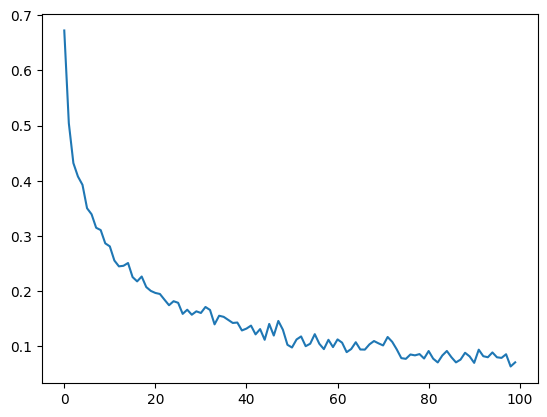

In [15]:
plt.plot(loss_1)


In [16]:
all_preds = []
all_targets = []
with torch.no_grad():
    for inputs, targets1, targets2 in dataloader_test:
        inputs = inputs.to(device)
        targets = targets1.to(device).to(torch.float32)  # importante: float32 para BCE

        outputs = model(inputs)  # salida [batch_size, 1]
        probs = torch.sigmoid(outputs)  # convertir a probabilidad
        preds = (probs > 0.5).int()  # binarizar

        all_preds.append(preds.cpu())
        all_targets.append(targets.unsqueeze(1).cpu())  

y_pred = torch.cat(all_preds).numpy()
y_true = torch.cat(all_targets).numpy()

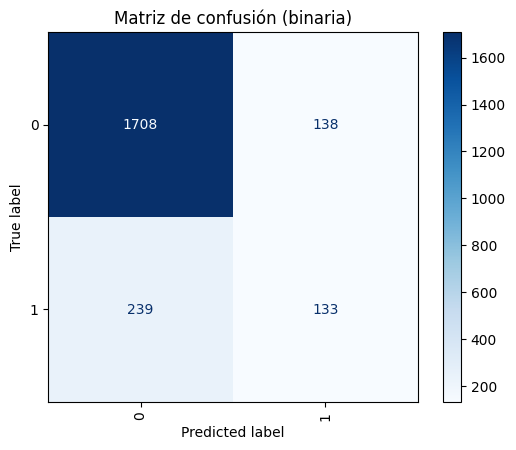

Accuracy: 0.8300270513976555
Precision: 0.4907749077490775
Recall: 0.3575268817204301
F1 Score: 0.41368584758942456


In [17]:

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap='Blues', xticks_rotation='vertical')
plt.title("Matriz de confusión (binaria)")
plt.show()

# Opcional: informe por clase
print("Accuracy:", accuracy_score(y_true, y_pred))
print("Precision:", precision_score(y_true, y_pred))
print("Recall:", recall_score(y_true, y_pred))
print("F1 Score:", f1_score(y_true, y_pred))